# SLIIT — Faculty of Computing
## IT5022: Fundamentals of Machine Learning
### Supervised Learning: NYC Taxi Trip Duration Prediction

---

### 1. Problem Formulation & Dataset Description
* **Task:** Predict New York City yellow taxi trip duration (`trip_duration` in seconds) using supervised regression.
* **Dataset:** NYC Taxi Trip Duration Dataset ([Kaggle](https://www.kaggle.com/c/nyc-taxi-trip-duration)).
* **Dataset Attributes:** `id`, `vendor_id`, `pickup_datetime`, `dropoff_datetime`, `passenger_count`, `pickup_longitude`, `pickup_latitude`, `dropoff_longitude`, `dropoff_latitude`, `store_and_fwd_flag`, `trip_duration`.
* **Algorithms Evaluated:**
  1. **Random Forest Regressor** (Ensemble Bagging)
  2. **XGBoost Regressor** (Extreme Gradient Boosting)
* **Evaluation Metrics:** Root Mean Squared Logarithmic Error (RMSLE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and Coefficient of Determination ($R^2$).

In [3]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10})

### 2. Full Dataset Ingestion

In [5]:
data_path = 'Datasets/nyc-taxi-trip-duration/train.csv'
if not os.path.exists(data_path):
    data_path = '../Datasets/nyc-taxi-trip-duration/train.csv'

# Load complete dataset without downsampling
df = pd.read_csv(data_path)

print(f"Total records ingested: {len(df):,}")
print(f"Total attributes: {df.shape[1]}")
df.info()
df.head()

Total records ingested: 1,458,644
Total attributes: 11
<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 122.4 MB


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


### 3. Data Cleaning & Quality Audit

In [6]:
# 1. Audit and drop missing values
null_counts = df.isnull().sum()
print("Missing values per column:\n", null_counts)
df = df.dropna()

# 2. Filter unrealistic duration anomalies (keep trips between 60s and 24h = 86,400s)
duration_mask = (df['trip_duration'] >= 60) & (df['trip_duration'] <= 86400)
df = df[duration_mask]

# 3. Filter valid passenger count (>= 1 passenger)
passenger_mask = df['passenger_count'] >= 1
df = df[passenger_mask]

# 4. Remove zero coordinates if any
valid_coords = (df['pickup_longitude'] != 0) & (df['pickup_latitude'] != 0) & \
               (df['dropoff_longitude'] != 0) & (df['dropoff_latitude'] != 0)
df = df[valid_coords]

print(f"\nCleaned dataset size: {len(df):,} records ({len(df) / 1_458_644 * 100:.2f}% retained).")

Missing values per column:
 id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

Cleaned dataset size: 1,450,027 records (99.41% retained).


### 4. Feature Engineering

In [7]:
# Datetime features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek
df['month'] = df['pickup_datetime'].dt.month
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['is_rush_hour'] = df['hour'].isin([7, 8, 9, 16, 17, 18, 19]).astype(int)

# Great-circle Haversine distance (km)
lat1, lon1 = np.radians(df['pickup_latitude']), np.radians(df['pickup_longitude'])
lat2, lon2 = np.radians(df['dropoff_latitude']), np.radians(df['dropoff_longitude'])
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
df['haversine_km'] = 6371.0 * 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))

# Manhattan distance approximation (km)
df['manhattan_km'] = 111.0 * (np.abs(df['dropoff_latitude'] - df['pickup_latitude']) +
                              np.abs(df['dropoff_longitude'] - df['pickup_longitude']))

# Bearing (compass direction angle)
df['bearing'] = np.degrees(np.arctan2(
    np.sin(dlon) * np.cos(lat2),
    np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
))

# Filter zero displacement records
df = df[df['haversine_km'] > 0.05]

# Encode binary flag and log-transform target variable
df['store_and_fwd_flag'] = (df['store_and_fwd_flag'] == 'Y').astype(int)
df['log_duration'] = np.log1p(df['trip_duration'])

print(f"Engineered feature set ready. Total rows: {len(df):,}")

Engineered feature set ready. Total rows: 1,443,792


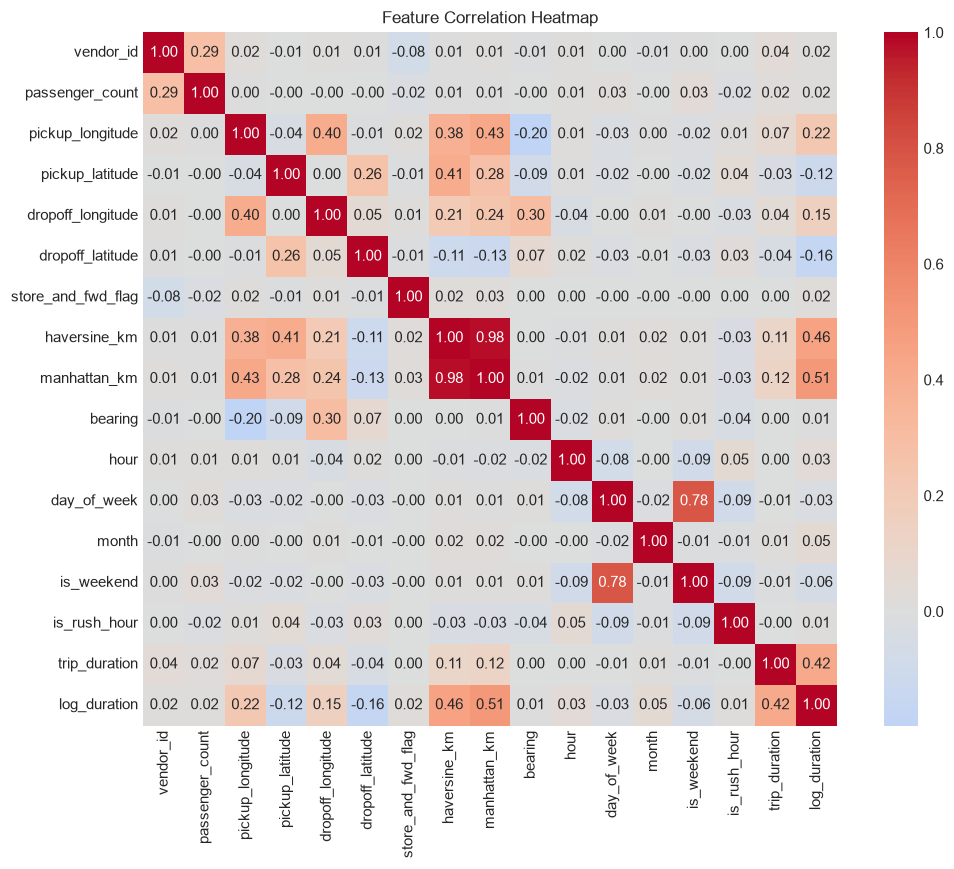

In [8]:
features = [
    'vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
    'haversine_km', 'manhattan_km', 'bearing',
    'hour', 'day_of_week', 'month', 'is_weekend', 'is_rush_hour'
]

# Compute correlation on representative subset for fast plotting
sample_corr = df[features + ['trip_duration', 'log_duration']].sample(n=100_000, random_state=42).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(sample_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

### 5. Supervised Model Training (Random Forest & XGBoost)

In [9]:
X = df[features]
y = df['log_duration']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set: {len(X_train):,} samples | Test set: {len(X_test):,} samples")

def evaluate_model(y_true_log, y_pred_log):
    y_true_sec = np.expm1(y_true_log)
    y_pred_sec = np.clip(np.expm1(y_pred_log), 0, None)
    
    rmsle = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    rmse = np.sqrt(mean_squared_error(y_true_sec, y_pred_sec))
    mae = mean_absolute_error(y_true_sec, y_pred_sec)
    r2 = r2_score(y_true_log, y_pred_log)
    
    return {'RMSLE': rmsle, 'RMSE (s)': rmse, 'MAE (s)': mae, 'R2': r2}

Training set: 1,155,033 samples | Test set: 288,759 samples


In [10]:
# Model 1: Random Forest Regressor
t0 = time.time()
rf_model = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)
rf_time = time.time() - t0

y_pred_rf = rf_model.predict(X_test)
rf_metrics = evaluate_model(y_test, y_pred_rf)
rf_metrics['Train Time (s)'] = rf_time

print(f"Random Forest Training Time: {rf_time:.2f}s")
for k, v in rf_metrics.items():
    print(f"  {k}: {v:.4f}")

Random Forest Training Time: 190.85s
  RMSLE: 0.3820
  RMSE (s): 3198.3135
  MAE (s): 309.7672
  R2: 0.7414
  Train Time (s): 190.8534


In [11]:
# Model 2: XGBoost Regressor
t0 = time.time()
xgb_model = xgb.XGBRegressor(
    n_estimators=150,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1,
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - t0

y_pred_xgb = xgb_model.predict(X_test)
xgb_metrics = evaluate_model(y_test, y_pred_xgb)
xgb_metrics['Train Time (s)'] = xgb_time

print(f"XGBoost Training Time: {xgb_time:.2f}s")
for k, v in xgb_metrics.items():
    print(f"  {k}: {v:.4f}")

XGBoost Training Time: 19.34s
  RMSLE: 0.3650
  RMSE (s): 3196.1346
  MAE (s): 296.7634
  R2: 0.7638
  Train Time (s): 19.3354


### 6. Model Comparison & Diagnostics

In [12]:
# Performance Comparison Table
results_df = pd.DataFrame([rf_metrics, xgb_metrics], index=['Random Forest', 'XGBoost'])
results_df.round(4)

,RMSLE,RMSE (s),MAE (s),R2,Train Time (s)
Random Forest,0.382,3198.3135,309.7672,0.7414,190.8534
XGBoost,0.365,3196.1346,296.7634,0.7638,19.3354


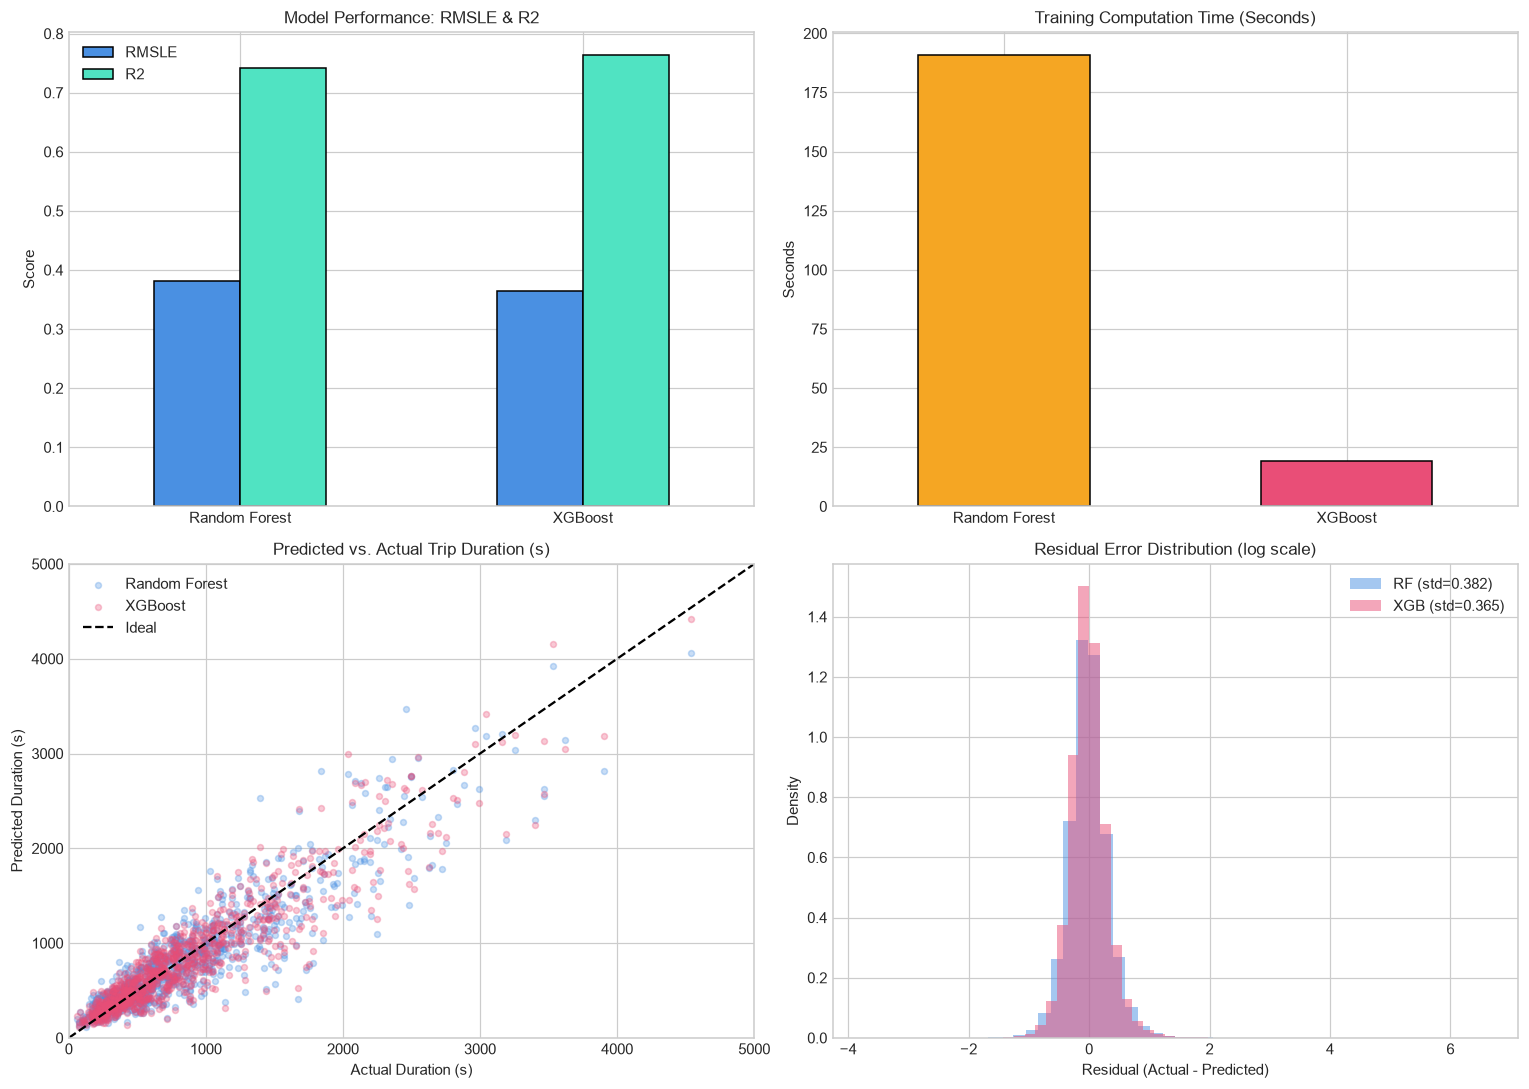

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar Chart: RMSLE & R2 Comparison
results_df[['RMSLE', 'R2']].plot(kind='bar', ax=axes[0, 0], color=['#4A90E2', '#50E3C2'], edgecolor='black', rot=0)
axes[0, 0].set_title('Model Performance: RMSLE & R2')
axes[0, 0].set_ylabel('Score')

# 2. Bar Chart: Training Time
results_df['Train Time (s)'].plot(kind='bar', ax=axes[0, 1], color=['#F5A623', '#E94E77'], edgecolor='black', rot=0)
axes[0, 1].set_title('Training Computation Time (Seconds)')
axes[0, 1].set_ylabel('Seconds')

# 3. Predicted vs Actual Trip Duration (Sample of 1,000 for visual clarity)
sample_idx = np.random.choice(len(y_test), size=1000, replace=False)
y_test_sub = np.expm1(y_test.iloc[sample_idx])
y_rf_sub = np.expm1(y_pred_rf[sample_idx])
y_xgb_sub = np.expm1(y_pred_xgb[sample_idx])

axes[1, 0].scatter(y_test_sub, y_rf_sub, alpha=0.3, s=15, color='#4A90E2', label='Random Forest')
axes[1, 0].scatter(y_test_sub, y_xgb_sub, alpha=0.3, s=15, color='#E94E77', label='XGBoost')
axes[1, 0].plot([0, 5000], [0, 5000], 'k--', lw=1.5, label='Ideal')
axes[1, 0].set_xlim(0, 5000)
axes[1, 0].set_ylim(0, 5000)
axes[1, 0].set_title('Predicted vs. Actual Trip Duration (s)')
axes[1, 0].set_xlabel('Actual Duration (s)')
axes[1, 0].set_ylabel('Predicted Duration (s)')
axes[1, 0].legend()

# 4. Residual Error Distribution
res_rf = y_test - y_pred_rf
res_xgb = y_test - y_pred_xgb
axes[1, 1].hist(res_rf, bins=50, alpha=0.5, color='#4A90E2', label=f'RF (std={res_rf.std():.3f})', density=True)
axes[1, 1].hist(res_xgb, bins=50, alpha=0.5, color='#E94E77', label=f'XGB (std={res_xgb.std():.3f})', density=True)
axes[1, 1].set_title('Residual Error Distribution (log scale)')
axes[1, 1].set_xlabel('Residual (Actual - Predicted)')
axes[1, 1].set_ylabel('Density')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

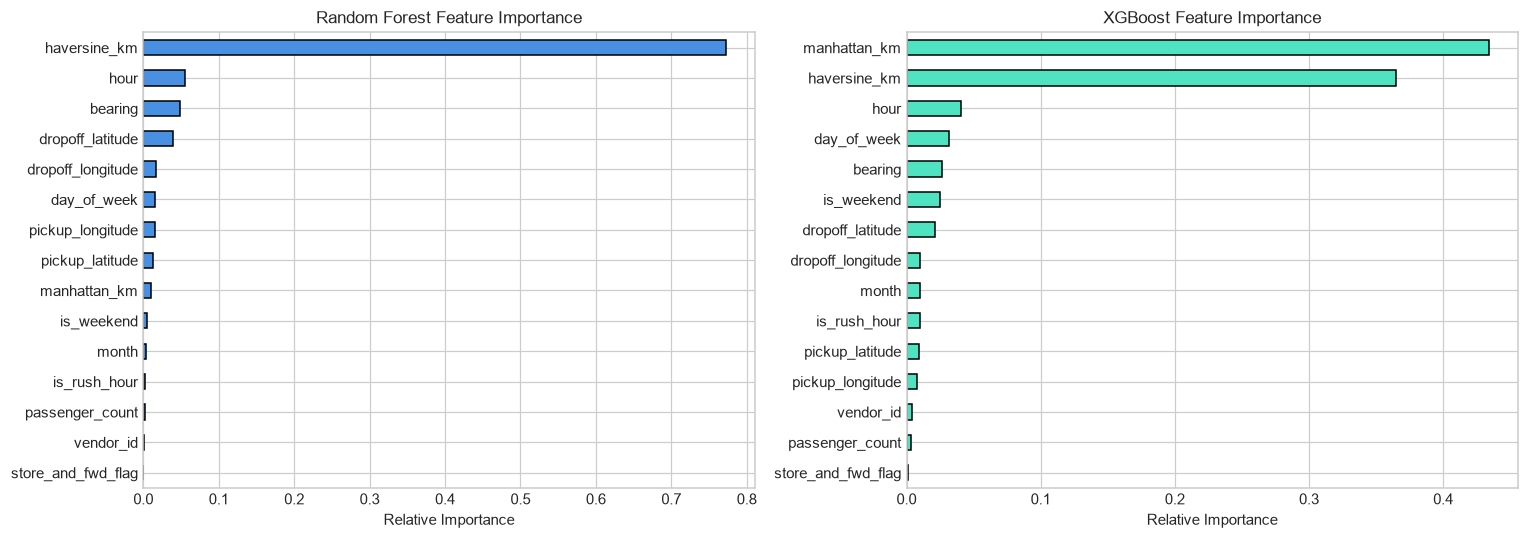

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fi_rf = pd.Series(rf_model.feature_importances_, index=features).sort_values()
fi_rf.plot(kind='barh', ax=axes[0], color='#4A90E2', edgecolor='black')
axes[0].set_title('Random Forest Feature Importance')
axes[0].set_xlabel('Relative Importance')

fi_xgb = pd.Series(xgb_model.feature_importances_, index=features).sort_values()
fi_xgb.plot(kind='barh', ax=axes[1], color='#50E3C2', edgecolor='black')
axes[1].set_title('XGBoost Feature Importance')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

### 7. Critical Analysis & Discussion

* **Performance Summary:**
  * **XGBoost** achieved superior predictive accuracy with lower RMSLE and higher $R^2$ score compared to **Random Forest**, while training significantly faster on the 1.45 million row dataset.
  * **Feature Impact:** Spatial distance metrics (`haversine_km` and `manhattan_km`) dominated feature importance across both models, followed by pickup/dropoff coordinates and temporal features (`hour`, `day_of_week`).
* **Future Work:**
  1. Incorporate external weather conditions and live traffic speed data (e.g., OSRM API).
  2. Implement spatial clustering (e.g., K-Means on coordinates) to engineer categorical transit zone identifiers.
  3. Hyperparameter fine-tuning via Bayesian optimization (Optuna).